Exploring a graph.

In [130]:
import requests, readline, sys, json
import numpy
import networkx as nx
import matplotlib as mpl
%matplotlib inline
%config InlineBacked.figure_format = 'svg'
import matplotlib.pyplot as plt
import matplotlib.cm as cmap
import seaborn

from query import *
from summary import *


vertexQ is a query to get all vertex labels:

In [131]:
vertexQ

'g.V().label().groupCount()'

getQuery gets the query results, and printResp prints a response

In [132]:
printResp(getQuery(vertexQ))


{'UnitDependency': '18378', 'UnnamedPipeObject': '67', 'MemoryObject': '4685', 'Event': '891421', 'FileObject': '3741', 'SrcSinkObject': '1079', 'Principal': '8', 'Subject': '110397', 'NetFlowObject': '3963'}


getGroupCountQuery runs a query and converts the resulting dictionary to a groupCount

In [133]:
getGroupCountQuery(vertexQ)

{'Event': 891421,
 'FileObject': 3741,
 'MemoryObject': 4685,
 'NetFlowObject': 3963,
 'Principal': 8,
 'SrcSinkObject': 1079,
 'Subject': 110397,
 'UnitDependency': 18378,
 'UnnamedPipeObject': 67}

getVertices collects the counts and number of incoming and outgoing edge labels for each vertex label.  For example:

In [78]:
vertices = getVertices()
print (vertices)

Vertex types/counts:
{'UnitDependency': {'count': 18378, 'in': {}, 'out': {'unit': 18378, 'dependentUnit': 18378}}, 'UnnamedPipeObject': {'count': 67, 'in': {'predicateObject': 84812}, 'out': {}}, 'MemoryObject': {'count': 4685, 'in': {'predicateObject2': 2206, 'predicateObject': 8449}, 'out': {}}, 'Event': {'count': 891421, 'in': {}, 'out': {'predicateObject2': 2368, 'subject': 891421, 'predicateObject': 891421}}, 'FileObject': {'count': 3741, 'in': {'predicateObject2': 162, 'predicateObject': 195985}, 'out': {}}, 'SrcSinkObject': {'count': 1079, 'in': {'predicateObject': 481247}, 'out': {}}, 'Principal': {'count': 8, 'in': {'localPrincipal': 110397}, 'out': {}}, 'Subject': {'count': 110397, 'in': {'unit': 18378, 'parentSubject': 110330, 'subject': 891421, 'predicateObject': 110529, 'dependentUnit': 18378}, 'out': {'localPrincipal': 110397, 'parentSubject': 110330}}, 'NetFlowObject': {'count': 3963, 'in': {'predicateObject': 10399}, 'out': {}}}


Likewise, getEdges collects the counts of edge labels and the number of vertex labels on the source and target of each edge.

In [79]:
edges = getEdges()
print (edges)

Edge types/counts:
{'predicateObject2': {'count': 2368, 'in': {'MemoryObject': 2206, 'FileObject': 162}, 'out': {'Event': 2368}}, 'unit': {'count': 18378, 'in': {'Subject': 18378}, 'out': {'UnitDependency': 18378}}, 'localPrincipal': {'count': 110397, 'in': {'Principal': 110397}, 'out': {'Subject': 110397}}, 'parentSubject': {'count': 110330, 'in': {'Subject': 110330}, 'out': {'Subject': 110330}}, 'subject': {'count': 891421, 'in': {'Subject': 891421}, 'out': {'Event': 891421}}, 'predicateObject': {'count': 891421, 'in': {'UnnamedPipeObject': 84812, 'MemoryObject': 8449, 'FileObject': 195985, 'SrcSinkObject': 481247, 'Subject': 110529, 'NetFlowObject': 10399}, 'out': {'Event': 891421}}, 'dependentUnit': {'count': 18378, 'in': {'Subject': 18378}, 'out': {'UnitDependency': 18378}}}


Hmm.  Not very readable.  Let's try to do better.  printSummary takes a dictionary in one of the above forms and prints out the results in a more structured way.

In [80]:
printSummary(vertices)

{}
 -> 
UnitDependency[18378]
 -> 
{unit[18378],
dependentUnit[18378]}

{predicateObject[84812]}
 -> 
UnnamedPipeObject[67]
 -> 
{}

{predicateObject2[2206],
predicateObject[8449]}
 -> 
MemoryObject[4685]
 -> 
{}

{}
 -> 
Event[891421]
 -> 
{predicateObject2[2368],
subject[891421],
predicateObject[891421]}

{predicateObject2[162],
predicateObject[195985]}
 -> 
FileObject[3741]
 -> 
{}

{predicateObject[481247]}
 -> 
SrcSinkObject[1079]
 -> 
{}

{localPrincipal[110397]}
 -> 
Principal[8]
 -> 
{}

{unit[18378],
parentSubject[110330],
subject[891421],
predicateObject[110529],
dependentUnit[18378]}
 -> 
Subject[110397]
 -> 
{localPrincipal[110397],
parentSubject[110330]}

{predicateObject[10399]}
 -> 
NetFlowObject[3963]
 -> 
{}



How about for edges?

In [134]:
printSummary(edges)

{MemoryObject[2206],
FileObject[162]}
 -> 
predicateObject2[2368]
 -> 
{Event[2368]}

{Subject[18378]}
 -> 
unit[18378]
 -> 
{UnitDependency[18378]}

{Principal[110397]}
 -> 
localPrincipal[110397]
 -> 
{Subject[110397]}

{Subject[110330]}
 -> 
parentSubject[110330]
 -> 
{Subject[110330]}

{Subject[891421]}
 -> 
subject[891421]
 -> 
{Event[891421]}

{UnnamedPipeObject[84812],
MemoryObject[8449],
FileObject[195985],
SrcSinkObject[481247],
Subject[110529],
NetFlowObject[10399]}
 -> 
predicateObject[891421]
 -> 
{Event[891421]}

{Subject[18378]}
 -> 
dependentUnit[18378]
 -> 
{UnitDependency[18378]}



Now let's build and visualize a (bipartite) graph.  Nodes will represent either node or edge labels, and edges represent that a node can have an in-edge or out-edge with a given label (or vice versa).

In [82]:
G = nx.DiGraph()


In [83]:
G.add_nodes_from(vertices,bipartite=0)
G.add_nodes_from(edges,bipartite=1)

In [84]:
for v in vertices.keys():
    for e in vertices[v]['in'].keys():
        G.add_edge(e,v)
    for e in vertices[v]['out'].keys():
        G.add_edge(v,e)

In [85]:
nx.is_bipartite(G)

True

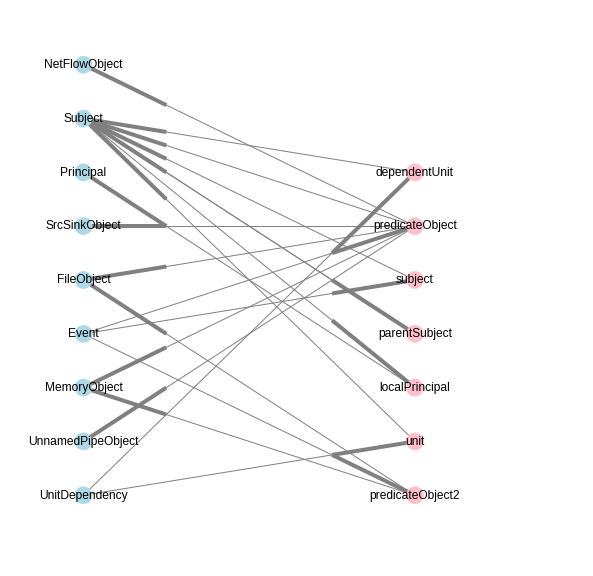

In [135]:
colors = ['lightblue' for x in vertices.keys()] + ['pink' for x in edges.keys()]
positions = {}
i = 1
for x in vertices.keys():
    positions[x] = (1,i)
    i = i + 1
i = 1
for x in edges.keys():
    positions[x] = (7,i)
    i = i + 1
fig = plt.figure(figsize=(10,10))
plt.gca().set_axis_off()   
plt.gca().set_xlim([-0.05, 10.05])    # add a little space around the plot
plt.gca().set_ylim([-0.05, 10.05])

nx.draw_networkx(G,pos=positions,
               with_labels=True,node_color=colors,edge_color='gray')

_ = plt.show()

Queries to find the edge labels coming into each node type.

In [136]:
getQuery("g.V().hasLabel('Subject').local(__.inE().label().groupCount()).dedup()")

[{'subject': '71'},
 {'predicateObject': '1'},
 {'subject': '213957'},
 {'predicateObject': '1', 'subject': '2'},
 {'parentSubject': '4', 'predicateObject': '1', 'subject': '14174'},
 {'predicateObject': '1', 'subject': '1'},
 {'subject': '7586'},
 {'subject': '28294'},
 {'parentSubject': '12', 'subject': '9875'},
 {'predicateObject': '1', 'subject': '3'},
 {'subject': '8872'},
 {'subject': '1913'},
 {'dependentUnit': '5', 'predicateObject': '1', 'subject': '1', 'unit': '2'},
 {'predicateObject': '1', 'unit': '2'},
 {'dependentUnit': '27', 'predicateObject': '1', 'subject': '1', 'unit': '22'},
 {'predicateObject': '1', 'subject': '10'},
 {'subject': '100921'},
 {'predicateObject': '1', 'subject': '19'},
 {'predicateObject': '1', 'unit': '1'},
 {'parentSubject': '7', 'predicateObject': '1', 'subject': '13'},
 {'predicateObject': '2', 'subject': '1489'},
 {'dependentUnit': '4', 'predicateObject': '1', 'subject': '1', 'unit': '1'},
 {'predicateObject': '1', 'subject': '36', 'unit': '2'},


In [137]:
getQuery("g.V().hasLabel('Event').local(__.inE().label().groupCount()).dedup()")

[{}]

In [138]:
getQuery("g.V().hasLabel('Principal').local(__.inE().label().groupCount()).dedup()")

[{'localPrincipal': '17'},
 {'localPrincipal': '110361'},
 {'localPrincipal': '7'},
 {'localPrincipal': '2'},
 {'localPrincipal': '5'},
 {'localPrincipal': '1'}]

In [139]:
getQuery("g.V().hasLabel('UnitDependency').local(__.inE().label().groupCount()).dedup()")

[{}]

In [141]:
getQuery("g.V().hasLabel('FileObject').local(__.inE().label().groupCount()).dedup()")

[{'predicateObject': '46'},
 {'predicateObject': '1'},
 {'predicateObject': '48'},
 {'predicateObject': '354'},
 {'predicateObject': '240'},
 {'predicateObject': '4'},
 {'predicateObject': '6'},
 {'predicateObject': '5'},
 {'predicateObject': '7'},
 {'predicateObject': '3'},
 {'predicateObject': '14'},
 {'predicateObject': '8'},
 {'predicateObject': '2'},
 {'predicateObject': '50'},
 {'predicateObject': '20'},
 {'predicateObject': '90'},
 {'predicateObject': '40'},
 {'predicateObject': '108'},
 {'predicateObject': '82'},
 {'predicateObject': '23'},
 {'predicateObject': '35'},
 {'predicateObject': '658'},
 {'predicateObject': '12'},
 {'predicateObject': '10'},
 {'predicateObject': '15'},
 {'predicateObject': '173'},
 {'predicateObject': '60'},
 {'predicateObject': '2496'},
 {'predicateObject': '16'},
 {'predicateObject': '30'},
 {'predicateObject': '45'},
 {'predicateObject': '92'},
 {'predicateObject': '9'},
 {'predicateObject': '13'},
 {'predicateObject': '294'},
 {'predicateObject2':

In [142]:
getQuery("g.V().hasLabel('NetFlowObject').local(__.inE().label().groupCount()).dedup()")

[{'predicateObject': '4'},
 {'predicateObject': '3'},
 {'predicateObject': '1'},
 {'predicateObject': '2'},
 {'predicateObject': '8'},
 {'predicateObject': '7'},
 {'predicateObject': '9'},
 {'predicateObject': '5'},
 {'predicateObject': '6'},
 {'predicateObject': '13'},
 {'predicateObject': '20'},
 {'predicateObject': '15'},
 {'predicateObject': '10'},
 {'predicateObject': '11'},
 {'predicateObject': '12'},
 {'predicateObject': '14'},
 {'predicateObject': '17'}]

In [143]:
getQuery("g.V().hasLabel('SrcSinkObject').local(__.inE().label().groupCount()).dedup()")

[{},
 {'predicateObject': '50'},
 {'predicateObject': '9'},
 {'predicateObject': '437'},
 {'predicateObject': '1'},
 {'predicateObject': '6000'},
 {'predicateObject': '6055'},
 {'predicateObject': '786'},
 {'predicateObject': '4659'},
 {'predicateObject': '2375'},
 {'predicateObject': '11818'},
 {'predicateObject': '2341'},
 {'predicateObject': '7303'},
 {'predicateObject': '6869'},
 {'predicateObject': '3009'},
 {'predicateObject': '5044'},
 {'predicateObject': '2871'},
 {'predicateObject': '957'},
 {'predicateObject': '956'},
 {'predicateObject': '159629'},
 {'predicateObject': '99708'},
 {'predicateObject': '372'},
 {'predicateObject': '5128'},
 {'predicateObject': '4'},
 {'predicateObject': '6'},
 {'predicateObject': '8'},
 {'predicateObject': '15'},
 {'predicateObject': '2'},
 {'predicateObject': '10'},
 {'predicateObject': '2889'},
 {'predicateObject': '2665'},
 {'predicateObject': '806'},
 {'predicateObject': '554'},
 {'predicateObject': '2777'},
 {'predicateObject': '852'},
 {'

In [144]:
getQuery("g.V().hasLabel('MemoryObject').local(__.inE().label().groupCount()).dedup()")

[{'predicateObject': '1'},
 {'predicateObject2': '1'},
 {'predicateObject': '331'},
 {'predicateObject': '2'},
 {'predicateObject2': '4'},
 {'predicateObject': '11'},
 {'predicateObject2': '5'},
 {'predicateObject2': '8'},
 {'predicateObject': '7'},
 {'predicateObject2': '2'},
 {'predicateObject2': '3'},
 {'predicateObject': '6'},
 {'predicateObject': '5'},
 {'predicateObject2': '7'},
 {'predicateObject': '3'},
 {'predicateObject': '4'},
 {'predicateObject2': '16'},
 {'predicateObject2': '193'},
 {'predicateObject': '168'},
 {'predicateObject': '15'},
 {'predicateObject': '20'},
 {'predicateObject': '8'},
 {'predicateObject': '10'},
 {'predicateObject': '57'},
 {'predicateObject': '29'},
 {'predicateObject2': '18'},
 {'predicateObject': '1092'},
 {'predicateObject': '137'},
 {'predicateObject': '2994'},
 {'predicateObject': '184'},
 {'predicateObject2': '12'}]

In [145]:
getQuery("g.V().hasLabel('UnnamedPipeObject').local(__.inE().label().groupCount()).dedup()")

[{'predicateObject': '7'},
 {'predicateObject': '2'},
 {'predicateObject': '4'},
 {'predicateObject': '8'},
 {'predicateObject': '18'},
 {'predicateObject': '9'},
 {'predicateObject': '5'},
 {'predicateObject': '43'},
 {'predicateObject': '190'},
 {'predicateObject': '182'},
 {'predicateObject': '6'},
 {'predicateObject': '19081'},
 {'predicateObject': '22726'},
 {'predicateObject': '19302'},
 {'predicateObject': '9171'},
 {'predicateObject': '17'},
 {'predicateObject': '1294'},
 {'predicateObject': '10'},
 {'predicateObject': '40'},
 {'predicateObject': '3'},
 {'predicateObject': '38'},
 {'predicateObject': '8931'},
 {'predicateObject': '1153'},
 {'predicateObject': '2310'}]

Queries to find the edge labels coming out of each node type.

In [129]:
getQuery("g.V().hasLabel('Subject').local(__.outE().label().groupCount()).dedup()")

[{'localPrincipal': '1'}, {'localPrincipal': '1', 'parentSubject': '1'}]

In [118]:
getQuery("g.V().hasLabel('Event').local(__.outE().label().groupCount()).dedup()")

[{'predicateObject': '1', 'subject': '1'},
 {'predicateObject': '1', 'predicateObject2': '1', 'subject': '1'}]

In [120]:
getQuery("g.V().hasLabel('Principal').local(__.outE().label().groupCount()).dedup()")

[{}]

In [121]:
getQuery("g.V().hasLabel('UnitDependency').local(__.outE().label().groupCount()).dedup()")

[{'dependentUnit': '1', 'unit': '1'}]

In [122]:
getQuery("g.V().hasLabel('FileObject').local(__.outE().label().groupCount()).dedup()")

[{}]

In [125]:
getQuery("g.V().hasLabel('NetFlowObject').local(__.outE().label().groupCount()).dedup()")

[{}]

In [124]:
getQuery("g.V().hasLabel('SrcSinkObject').local(__.outE().label().groupCount()).dedup()")

[{}]

In [126]:
getQuery("g.V().hasLabel('MemoryObject').local(__.outE().label().groupCount()).dedup()")

[{}]

In [127]:
getQuery("g.V().hasLabel('UnnamedPipeObject').local(__.outE().label().groupCount()).dedup()")

[{}]